In [15]:
import os
import glob
import pandas as pd
import numpy as np

from scipy import optimize
from sklearn.model_selection import train_test_split
from matplotlib import pyplot
from mpl_toolkits.mplot3d import Axes3D

%matplotlib inline

In [16]:
ruta_csv = os.path.join('datasets', 'HMCC.csv')

df = pd.read_csv(ruta_csv)

X_raw = df.iloc[:, 1:].values
y_raw = df.iloc[:, 0].values

n_muestras_deseadas = 90000

if X_raw.shape[0] > n_muestras_deseadas: X_sub, _, y_sub, _ = train_test_split(X_raw, y_raw, 
        train_size=n_muestras_deseadas, 
        random_state=42, 
        stratify=y_raw
    )
else:
    X_sub, y_sub = X_raw, y_raw

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_sub, y_sub, test_size=0.20, random_state=42, stratify=y_sub)

X_train = X_train_raw.reshape(X_train_raw.shape[0], -1)
X_test = X_test_raw.reshape(X_test_raw.shape[0], -1)

num_labels = len(np.unique(y_raw))

# No se requiere reemplazo de etiquetas ya que vienen indexadas desde 0
# y_train[y_train == 36] = 0  <-- NO ES NECESARIO
# y_test[y_test == 36] = 0   <-- NO ES NECESARIO

m = y_train.size
print(f"Número de ejemplos de entrenamiento (m): {m}")

print(f"X_train dimensiones: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test dimensiones:  {X_test.shape}, y_test:  {y_test.shape}")

Número de ejemplos de entrenamiento (m): 72000
X_train dimensiones: (72000, 784), y_train: (72000,)
X_test dimensiones:  (18000, 784), y_test:  (18000,)


In [17]:
print(X_train)
print(y_train)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
[40  8 41 ... 22  6  1]


In [18]:
def displayData(X, example_width=None, figsize=(10, 10)):
    
    if X.ndim == 2:
        m, n = X.shape
    elif X.ndim == 1:
        n = X.size
        m = 1
        X = X[None]
    else:
        raise IndexError('La entrada X debe ser 1 o 2 dimensinal.')

    example_width = example_width or int(np.round(np.sqrt(n)))
    example_height = n / example_width

    display_rows = int(np.floor(np.sqrt(m)))
    display_cols = int(np.ceil(m / display_rows))

    fig, ax_array = pyplot.subplots(display_rows, display_cols, figsize=figsize)
    fig.subplots_adjust(wspace=0.025, hspace=0.025)

    ax_array = [ax_array] if m == 1 else ax_array.ravel()

    for i, ax in enumerate(ax_array):
        ax.imshow(X[i].reshape(example_width, example_width, order='F'),
                  cmap='Greys', extent=[0, 1, 0, 1])
        ax.axis('off')

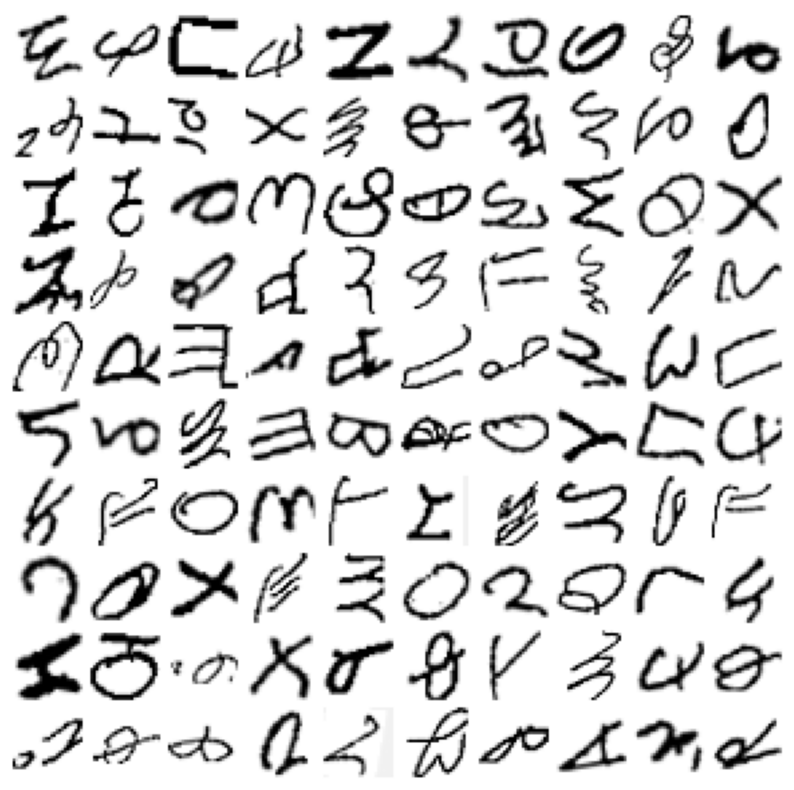

In [19]:
rand_indices = np.random.choice(m, 100, replace=False)
sel = X_train[rand_indices, :]

displayData(sel)

In [20]:
theta_t = np.array([-2, -1, 1, 2], dtype=float)

X_t = np.concatenate([np.ones((5, 1)), np.arange(1, 16).reshape(5, 3, order='F')/10.0], axis=1)
print(X_t)

y_t = np.array([1, 0, 1, 0, 1])

lambda_t = 3

[[1.  0.1 0.6 1.1]
 [1.  0.2 0.7 1.2]
 [1.  0.3 0.8 1.3]
 [1.  0.4 0.9 1.4]
 [1.  0.5 1.  1.5]]


In [21]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

In [22]:
def lrCostFunction(theta, X, y, lambda_):

    m = y.size

    if y.dtype == bool:
        y = y.astype(int)

    J = 0
    grad = np.zeros(theta.shape)

    h = sigmoid(X.dot(theta.T))

    temp = theta
    temp[0] = 0

    J = (1 / m) * np.sum(-y.dot(np.log(h)) - (1 - y).dot(np.log(1 - h))) + (lambda_ / (2 * m)) * np.sum(np.square(temp))

    grad = (1 / m) * (h - y).dot(X)
    grad = grad + (lambda_ / m) * temp

    return J, grad

In [23]:
J, grad = lrCostFunction(theta_t, X_t, y_t, lambda_t)

print('Costo         : {:.6f}'.format(J))
print('Costo esperadot: 2.534819')
print('-----------------------')
print('Gradientes:')
print(' [{:.6f}, {:.6f}, {:.6f}, {:.6f}]'.format(*grad))
print('Gradientes esperados:')
print(' [0.146561, -0.548558, 0.724722, 1.398003]')

Costo         : 2.534819
Costo esperadot: 2.534819
-----------------------
Gradientes:
 [0.146561, -0.548558, 0.724722, 1.398003]
Gradientes esperados:
 [0.146561, -0.548558, 0.724722, 1.398003]


In [24]:
def oneVsAll(X, y, num_labels, lambda_):
    
    # algunas variables utiles
    m, n = X.shape

    all_theta = np.zeros((num_labels, n + 1))

    # Agrega unos a la matriz X
    X = np.concatenate([np.ones((m, 1)), X], axis=1)

    for c in np.arange(num_labels):
        initial_theta = np.zeros(n + 1)
        options = {'maxiter': 50}
        res = optimize.minimize(lrCostFunction,initial_theta,(X, (y == c), lambda_),jac=True,method='CG',options=options)

        all_theta[c] = res.x

    return all_theta

In [25]:
lambda_t = 0.1
all_theta = oneVsAll(X_train, y_train, num_labels, lambda_t)

print("Dimensiones de all_theta:", all_theta.shape)

C:\Users\marco\AppData\Local\Temp\ipykernel_20716\2831633526.py:2: RuntimeWarning: overflow encountered in exp
  return 1.0 / (1.0 + np.exp(-z))
C:\Users\marco\AppData\Local\Temp\ipykernel_20716\2899506209.py:16: RuntimeWarning: divide by zero encountered in log
  J = (1 / m) * np.sum(-y.dot(np.log(h)) - (1 - y).dot(np.log(1 - h))) + (lambda_ / (2 * m)) * np.sum(np.square(temp))
C:\Users\marco\AppData\Local\Temp\ipykernel_20716\2899506209.py:16: RuntimeWarning: invalid value encountered in dot
  J = (1 / m) * np.sum(-y.dot(np.log(h)) - (1 - y).dot(np.log(1 - h))) + (lambda_ / (2 * m)) * np.sum(np.square(temp))
C:\Users\marco\AppData\Local\Temp\ipykernel_20716\2831633526.py:2: RuntimeWarning: overflow encountered in exp
  return 1.0 / (1.0 + np.exp(-z))
C:\Users\marco\AppData\Local\Temp\ipykernel_20716\2899506209.py:16: RuntimeWarning: divide by zero encountered in log
  J = (1 / m) * np.sum(-y.dot(np.log(h)) - (1 - y).dot(np.log(1 - h))) + (lambda_ / (2 * m)) * np.sum(np.square(temp))


Dimensiones de all_theta: (66, 785)


In [26]:
def predictOneVsAll(all_theta, X):
    m = X.shape[0]
    num_labels = all_theta.shape[0]

    p = np.zeros(m)

    X = np.concatenate([np.ones((m, 1)), X], axis=1)
    p = np.argmax(sigmoid(X.dot(all_theta.T)), axis = 1)

    return p

(72000, 784)
Precision del conjuto de entrenamiento: 47.38%
(12, 784)
(12, 785)
[ 8 39  2 32 63 23  7 58 17 48 27 58]


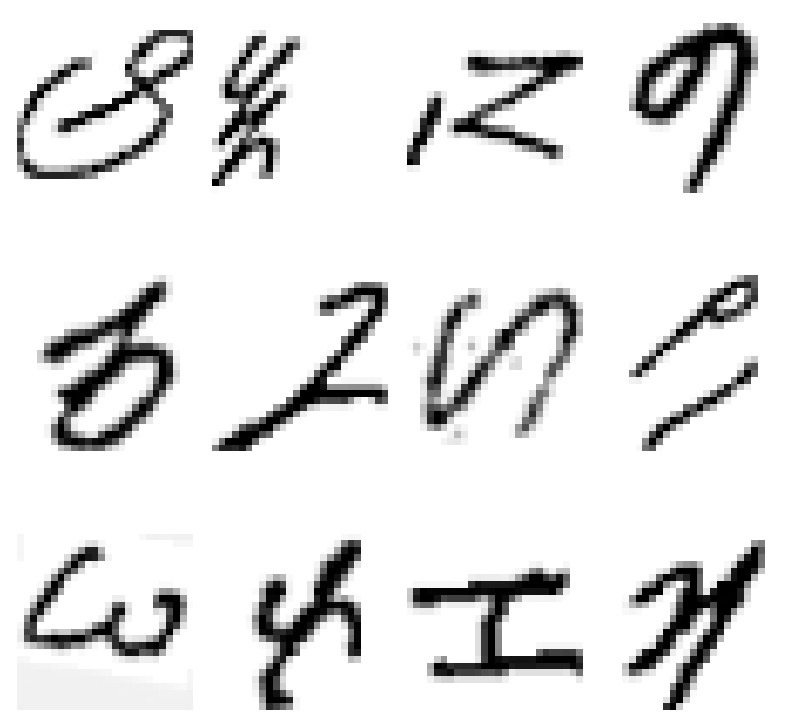

In [27]:
print(X_train.shape)
pred = predictOneVsAll(all_theta, X_train)
print('Precision del conjuto de entrenamiento: {:.2f}%'.format(np.mean(pred == y_train) * 100))
XPrueba = X_train[2001:2013, :].copy()
print(XPrueba.shape)
#print(np.ones((1)))
#print(XPrueba)
#p = np.zeros(1)
XPrueba = np.concatenate([np.ones((12, 1)), XPrueba], axis=1)
print(XPrueba.shape)
p = np.argmax(sigmoid(XPrueba.dot(all_theta.T)), axis = 1)
print(p)

displayData(X_train[2001:2013, :])